# Класифікатор життєвого етапу за віком
### Навчання з учителем · логістична регресія · проєкт «Поради бабусі»

**Задача.** Користувач у короткому опитуванні на сайті вказує свій вік. Модель оцінює, на якому життєвому етапі людина найімовірніше перебуває, і за цим сайт підбирає тему порад і бабусю-порадницю:

| Етап (клас) | Тема порад | Яка бабуся підійде |
|---|---|---|
| Ще не в шлюбі | Стосунки й побачення | та, що вміє говорити з молоддю про кохання |
| У шлюбі | Сім’я й шлюб | та, що прожила довгий шлюб і виростила дітей |
| Розлучення / окремо | Підтримка | та, що сама пережила розрив і почала знову |
| Вдівство | Доброта й підтримка | та, що знає, як жити після втрати |

Це **навчання з учителем**: у навчальних даних для кожної людини відомий правильний етап (мітка), і модель вчиться відтворювати його за ознаками. **Логістична регресія** — регресійна модель, яка видає ймовірності класів, тому це «регресійний класифікатор».

Прогноз — лише підказка: на сайті користувач бачить ймовірності й може сам обрати іншу тему.

## 1. Дані

**UCI Adult (Census Income)** — відкритий набір даних перепису населення США 1994 року, 48 842 записи. Автори: Barry Becker, Ronny Kohavi. Ліцензія CC BY 4.0. Джерело: https://archive.ics.uci.edu/dataset/2/adult (тут використано копію з GitHub, `adult.csv` лежить поруч із ноутбуком).

Основна модель використовує лише `age` (вік) як ознаку і `marital_status` (сімейний стан) як мітку. Стовпець `sex` (стать) знадобиться в розділі 6, щоб перевірити, чи варто додавати стать.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report, confusion_matrix

COLS = ['age','workclass','fnlwgt','education','education_num','marital_status','occupation',
        'relationship','race','sex','capital_gain','capital_loss','hours_per_week','native_country','income']
URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv'
src = 'adult.csv' if os.path.exists('adult.csv') else URL
df = pd.read_csv(src, header=None, names=COLS, skipinitialspace=True)
print('Рядків:', len(df), '| джерело:', src)
df[['age','sex','marital_status']].head()

Рядків: 48842 | джерело: adult.csv


,age,sex,marital_status
0,39,Male,Never-married
1,50,Male,Married-civ-spouse
2,38,Male,Divorced
3,53,Male,Married-civ-spouse
4,28,Female,Married-civ-spouse


## 2. Мітка: 4 життєві етапи

Сім варіантів сімейного стану об’єднуємо в чотири етапи. «Окремо» (Separated) і «чоловік/дружина відсутні» (Married-spouse-absent) за змістом ближчі до розлучення, тому йдуть у той самий клас.

In [2]:
STAGE = {
    'Never-married': 'single',
    'Married-civ-spouse': 'married', 'Married-AF-spouse': 'married',
    'Divorced': 'divorced', 'Separated': 'divorced', 'Married-spouse-absent': 'divorced',
    'Widowed': 'widowed',
}
LABEL_UA = {'single': 'Ще не в шлюбі', 'married': 'У шлюбі', 'divorced': 'Розлучення / окремо', 'widowed': 'Вдівство'}
ORDER = ['single', 'married', 'divorced', 'widowed']

df['stage'] = df['marital_status'].map(STAGE)
df['male'] = (df['sex'] == 'Male').astype(int)
assert df['stage'].notna().all()

counts = df['stage'].value_counts().reindex(ORDER)
pd.DataFrame({'етап': [LABEL_UA[s] for s in ORDER], 'кількість': counts.values,
              'частка, %': (counts.values / len(df) * 100).round(1)})

,етап,кількість,"частка, %"
0,Ще не в шлюбі,16117,33.0
1,У шлюбі,22416,45.9
2,Розлучення / окремо,8791,18.0
3,Вдівство,1518,3.1


## 3. Як етап залежить від віку

Частка кожного етапу в кожному віці (17–80). Видно, чому одна пряма лінія по віку не підійде: частка «у шлюбі» спершу зростає, а після 60 спадає, бо зростає вдівство. Тому в ознаки додамо вік у квадраті й кубі.

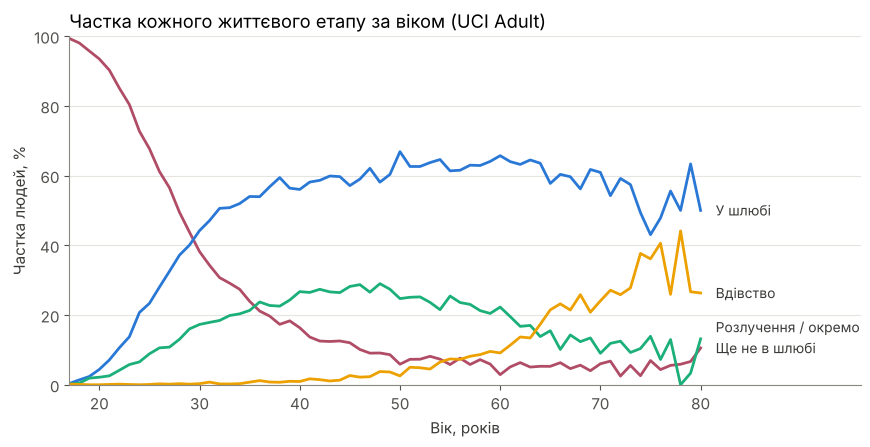

In [3]:
COLORS = {'single': '#b04c66', 'married': '#2a78d6', 'divorced': '#1baf7a', 'widowed': '#eda100'}

def end_labels(ax, x, ys, min_gap=6):
    # підписи біля кінців ліній, розсунуті, щоб не налазили один на одного
    items = sorted(ys.items(), key=lambda kv: kv[1])
    pos = []
    for s, y in items:
        y = max(y, pos[-1] + min_gap) if pos else y
        pos.append(y)
        ax.text(x, y, LABEL_UA[s], color='#3a3a38', va='center', fontsize=10)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#8a8780', 'axes.labelcolor': '#3a3a38', 'xtick.color': '#52514e', 'ytick.color': '#52514e'})

share = (df[df.age <= 80].groupby('age')['stage'].value_counts(normalize=True).unstack().reindex(columns=ORDER).fillna(0))
fig, ax = plt.subplots(figsize=(9, 4.6))
for s in ORDER:
    ax.plot(share.index, share[s] * 100, color=COLORS[s], lw=2)
end_labels(ax, 81.5, {s: share[s].iloc[-1] * 100 for s in ORDER})
ax.set_xlim(17, 96); ax.set_ylim(0, 100); ax.set_xticks(range(20, 81, 10))
ax.set_xlabel('Вік, років'); ax.set_ylabel('Частка людей, %')
ax.set_title('Частка кожного життєвого етапу за віком (UCI Adult)', loc='left')
ax.grid(axis='y', color='#e6e4df', lw=0.8)
plt.tight_layout(); plt.show()

## 4. Ознаки

Модель — класифікатор **за віком**: вона отримує лише вік, який користувач вводить в опитуванні.

* `a` — вік, стандартизований за навчальною вибіркою. Вік понад 80 рахуємо як 80: старших людей у даних мало, і поліном без цього обмеження «загинається» на краях;
* `a²`, `a³` — щоб модель могла описати криві з горбом (шлюб) і різким зростанням у старшому віці (вдівство). Без них логістична регресія вміє лише «більше віку → більше або менше ймовірність».

Ту саму функцію ознак повторено на сайті мовою JavaScript, тож прогнози в браузері й тут однакові.

In [4]:
X_raw = df[['age', 'male']]
y = df['stage']
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X_raw, y, test_size=0.2, stratify=y, random_state=42)

AGE_MIN, AGE_MAX = 17, 80
AGE_MU = float(X_tr_raw['age'].clip(AGE_MIN, AGE_MAX).mean())
AGE_SD = float(X_tr_raw['age'].clip(AGE_MIN, AGE_MAX).std())
FEATURES = ['a', 'a^2', 'a^3']

def make_features(age):
    a = (np.clip(np.asarray(age, dtype=float), AGE_MIN, AGE_MAX) - AGE_MU) / AGE_SD
    return np.column_stack([a, a**2, a**3])

X_tr = make_features(X_tr_raw['age'])
X_te = make_features(X_te_raw['age'])
print(f'Навчальна вибірка: {len(X_tr)}, тестова: {len(X_te)}; середній вік {AGE_MU:.2f}, ст. відхилення {AGE_SD:.2f}')

Навчальна вибірка: 39073, тестова: 9769; середній вік 38.66, ст. відхилення 13.68


## 5. Навчання і порівняння моделей

Порівнюємо варіанти на тестовій вибірці (20 % даних, яких модель не бачила):

1. **Базова модель** — завжди каже найчастіший клас («у шлюбі»). Будь-яка корисна модель має бути кращою.
2. **Вік, пряма лінія** — логістична регресія на одній ознаці `a`.
3. **Вік, поліном 3-го степеня** — основна модель (`a`, `a²`, `a³`).

Метрики: **accuracy** (частка правильних відповідей), **macro F1** (середнє F1 по класах, чесніше для рідкісного вдівства) і **log loss** (наскільки хороші ймовірності; менше — краще).

In [5]:
def evaluate(name, model, Xa, Xb):
    model.fit(Xa, y_tr)
    pred, proba = model.predict(Xb), model.predict_proba(Xb)
    return {'модель': name, 'accuracy': accuracy_score(y_te, pred),
            'macro F1': f1_score(y_te, pred, average='macro'), 'log loss': log_loss(y_te, proba, labels=model.classes_)}

rows = [
    evaluate('Базова (найчастіший клас)', DummyClassifier(strategy='prior'), X_tr, X_te),
    evaluate('Вік, пряма', make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), X_tr[:, :1], X_te[:, :1]),
]
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
rows.append(evaluate('Вік, поліном (основна)', model, X_tr, X_te))
results = pd.DataFrame(rows).set_index('модель').round(3)
results

,accuracy,macro F1,log loss
модель,,,
Базова (найчастіший клас),0.459,0.157,1.140
"Вік, пряма",0.610,0.361,0.934
"Вік, поліном (основна)",0.622,0.348,0.909


### Перехресна перевірка

Щоб переконатися, що результат не випадковий через одне розбиття, проганяємо 5-кратну стратифіковану перехресну перевірку на навчальній вибірці.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), X_tr, y_tr, cv=cv, scoring='accuracy')
print('Accuracy по фолдах:', np.round(cv_acc, 3), '| середнє', round(cv_acc.mean(), 3), '±', round(cv_acc.std(), 3))

Accuracy по фолдах: [0.628 0.62  0.625 0.631 0.623] | середнє 0.625 ± 0.004


## 6. Експеримент: чи додавати стать?

Якщо додати стать (і її взаємодію з віком), accuracy зростає. Але перш ніж радіти, перевіримо, звідки цей приріст.

In [7]:
def make_features_sex(age, male):
    a = (np.clip(np.asarray(age, dtype=float), AGE_MIN, AGE_MAX) - AGE_MU) / AGE_SD
    m = np.asarray(male, dtype=float)
    return np.column_stack([a, a**2, a**3, m, a*m, a**2*m])

model_sex = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
exp_row = evaluate('Вік + стать (експеримент)', model_sex,
                   make_features_sex(X_tr_raw['age'], X_tr_raw['male']), make_features_sex(X_te_raw['age'], X_te_raw['male']))
display(pd.concat([results, pd.DataFrame([exp_row]).set_index('модель').round(3)]))

bias = pd.crosstab(df['sex'], df['stage'], normalize='index').reindex(columns=ORDER) * 100
bias.columns = [LABEL_UA[s] for s in ORDER]
bias.index = ['Жінки', 'Чоловіки']
bias.round(1)

,accuracy,macro F1,log loss
модель,,,
Базова (найчастіший клас),0.459,0.157,1.140
"Вік, пряма",0.610,0.361,0.934
"Вік, поліном (основна)",0.622,0.348,0.909
Вік + стать (експеримент),0.684,0.591,0.804


,Ще не в шлюбі,У шлюбі,Розлучення / окремо,Вдівство
Жінки,44.6,15.5,32.3,7.6
Чоловіки,27.3,61.0,10.9,0.9


**Висновок: стать не додаємо.** У цьому наборі заміжніми записано лише ~15 % жінок проти ~61 % чоловіків. Це не правда про суспільство, а особливість вибірки (у набір потрапляли переважно працюючі люди, а в 1994 році заміжні жінки працювали рідше). Модель зі статтю «вивчила» цей перекіс і, наприклад, 58-річній жінці дає найвищу ймовірність розлучення. На сайті це означало б, що жінкам частіше пропонують поради про розрив. Тому основна модель — **лише за віком**: трохи нижча точність, зате без чужого перекосу.

Це типова пастка навчання з учителем: модель відтворює не світ, а дані, на яких вчилася.

## 7. Якість по класах

Звіт і матриця помилок для основної моделі. Рядки — правда, стовпці — прогноз, у клітинках частка рядка.

                     precision    recall  f1-score   support

      Ще не в шлюбі      0.738     0.661     0.698      3224
            У шлюбі      0.573     0.880     0.694      4483
Розлучення / окремо      0.000     0.000     0.000      1758
           Вдівство      0.000     0.000     0.000       304

           accuracy                          0.622      9769
          macro avg      0.328     0.385     0.348      9769
       weighted avg      0.507     0.622     0.549      9769



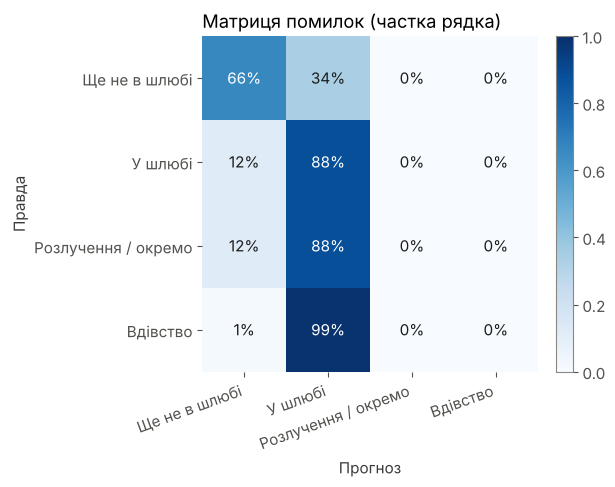

In [8]:
pred = model.predict(X_te)
print(classification_report(y_te, pred, labels=ORDER, target_names=[LABEL_UA[s] for s in ORDER], digits=3, zero_division=0))

cm = confusion_matrix(y_te, pred, labels=ORDER, normalize='true')
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4), [LABEL_UA[s] for s in ORDER], rotation=20, ha='right')
ax.set_yticks(range(4), [LABEL_UA[s] for s in ORDER])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]*100:.0f}%', ha='center', va='center', color='white' if cm[i, j] > 0.55 else '#1b1b1a', fontsize=11)
ax.set_xlabel('Прогноз'); ax.set_ylabel('Правда')
ax.set_title('Матриця помилок (частка рядка)', loc='left')
for s in ax.spines.values(): s.set_visible(False)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

**Як читати.** Молодих людей «не в шлюбі» і людей «у шлюбі» модель розрізняє добре (recall 0,66 і 0,88). Розлучення й вдівство вона не обирає як найімовірніший клас у жодному віці: вік — єдина підказка моделі, а в кожному віці одружених у даних більше, ніж розлучених чи вдівців. Це не помилка коду, а межа однієї ознаки. Тому сайт показує не лише один прогноз, а **всі ймовірності**, і рекомендує теми за ними, а не тільки за переможцем.

## 8. Ймовірності моделі проти реальних даних

Суцільні лінії — ймовірності моделі, тонкі пунктирні — фактичні частки в даних.

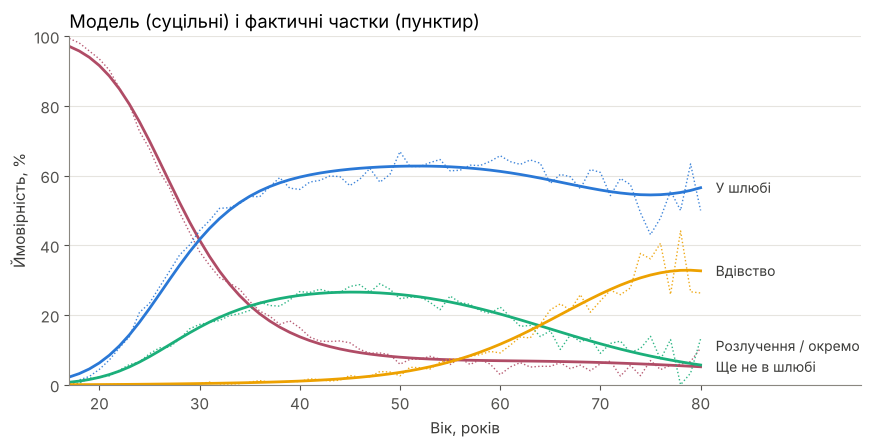

In [9]:
ages = np.arange(17, 81)
P = model.predict_proba(make_features(ages))
emp = df[df.age <= 80].groupby('age')['stage'].value_counts(normalize=True).unstack().reindex(columns=ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(9, 4.6))
for s in ORDER:
    k = list(model.classes_).index(s)
    ax.plot(emp.index, emp[s] * 100, color=COLORS[s], lw=1, ls=':', alpha=0.9)
    ax.plot(ages, P[:, k] * 100, color=COLORS[s], lw=2)
end_labels(ax, 81.5, {s: P[-1, list(model.classes_).index(s)] * 100 for s in ORDER})
ax.set_xlim(17, 96); ax.set_ylim(0, 100); ax.set_xticks(range(20, 81, 10))
ax.set_xlabel('Вік, років'); ax.set_ylabel('Ймовірність, %')
ax.set_title('Модель (суцільні) і фактичні частки (пунктир)', loc='left')
ax.grid(axis='y', color='#e6e4df', lw=0.8)
plt.tight_layout(); plt.show()

## 9. Приклади прогнозів

Те, що побачить користувач певного віку.

In [10]:
examples = [19, 24, 31, 45, 58, 74, 85]
P = model.predict_proba(make_features(examples))
tab = pd.DataFrame(P * 100, columns=[LABEL_UA[c] for c in model.classes_]).round(0).astype(int)
tab.insert(0, 'вік', examples)
tab[['вік'] + [LABEL_UA[s] for s in ORDER]]

,вік,Ще не в шлюбі,У шлюбі,Розлучення / окремо,Вдівство
0,19,94,5,2,0
1,24,75,18,7,0
2,31,37,45,18,0
3,45,10,62,27,2
4,58,7,62,22,9
5,74,6,55,9,31
6,85,5,57,6,33


## 10. Від прогнозу до поради

Ймовірності етапів перетворюємо на ваги тем. Кожен етап «голосує» за свої теми, і тема отримує суму ймовірностей. Бабусь сайт сортує за тим, наскільки їхні теми збігаються з цими вагами.

In [11]:
TOPICS = {  # етап -> внесок у теми порад
    'single':   {'relationships': 1.0, 'kindness': 0.2},
    'married':  {'family': 1.0, 'relationships': 0.4},
    'divorced': {'support': 1.0, 'relationships': 0.3},
    'widowed':  {'support': 0.7, 'kindness': 0.8},
}
TOPIC_UA = {'relationships': 'Стосунки', 'family': 'Сім’я', 'kindness': 'Доброта', 'support': 'Підтримка'}

def topic_weights(age):
    p = dict(zip(model.classes_, model.predict_proba(make_features([age]))[0]))
    w = {}
    for stage, prob in p.items():
        for t, v in TOPICS[stage].items():
            w[t] = w.get(t, 0) + prob * v
    return dict(sorted(w.items(), key=lambda kv: -kv[1]))

for a in [22, 40, 70]:
    w = topic_weights(a)
    print(f'{a} р.: ' + ', '.join(f'{TOPIC_UA[t]} {v:.2f}' for t, v in w.items()))

22 р.: Стосунки 0.90, Доброта 0.17, Сім’я 0.11, Підтримка 0.04
40 р.: Сім’я 0.60, Стосунки 0.45, Підтримка 0.26, Доброта 0.04
70 р.: Сім’я 0.56, Стосунки 0.32, Підтримка 0.30, Доброта 0.22


## 11. Експорт моделі для сайту

Зберігаємо все, що потрібно браузеру: параметри стандартизації віку, параметри `StandardScaler`, коефіцієнти й зсуви логістичної регресії, метрики. Сайт рахує `z = W·x + b` і `softmax(z)` — ті самі числа, що й `predict_proba` тут.

In [12]:
scaler, clf = model.named_steps['standardscaler'], model.named_steps['logisticregression']
main = results.loc['Вік, поліном (основна)']
export = {
    'name': 'life-stage-by-age', 'algorithm': 'multinomial logistic regression (scikit-learn)',
    'dataset': 'UCI Adult (Census Income), 1994, CC BY 4.0', 'n_train': int(len(X_tr)), 'n_test': int(len(X_te)),
    'features': FEATURES, 'age_min': AGE_MIN, 'age_max': AGE_MAX, 'age_mu': AGE_MU, 'age_sd': AGE_SD,
    'scaler_mean': scaler.mean_.round(8).tolist(), 'scaler_scale': scaler.scale_.round(8).tolist(),
    'classes': clf.classes_.tolist(), 'coef': clf.coef_.round(8).tolist(), 'intercept': clf.intercept_.round(8).tolist(),
    'metrics': {'accuracy': round(float(main['accuracy']), 3), 'macro_f1': round(float(main['macro F1']), 3),
                'log_loss': round(float(main['log loss']), 3),
                'baseline_accuracy': round(float(results.loc['Базова (найчастіший клас)', 'accuracy']), 3),
                'cv_accuracy_mean': round(float(cv_acc.mean()), 3),
                'with_sex_accuracy_rejected': round(float(exp_row['accuracy']), 3)},
    'topics': TOPICS,
}
with open('model.json', 'w', encoding='utf-8') as f:
    json.dump(export, f, ensure_ascii=False, indent=1)

# контрольні значення: сайт має дати ті самі ймовірності
check = {str(a): dict(zip(clf.classes_, np.round(model.predict_proba(make_features([a]))[0], 4).tolist())) for a in [19, 45, 74]}
print(json.dumps(check, ensure_ascii=False, indent=1))

{
 "19": {
  "divorced": 0.0151,
  "married": 0.0453,
  "single": 0.9392,
  "widowed": 0.0004
 },
 "45": {
  "divorced": 0.2657,
  "married": 0.6183,
  "single": 0.097,
  "widowed": 0.019
 },
 "74": {
  "divorced": 0.0885,
  "married": 0.5451,
  "single": 0.0598,
  "widowed": 0.3066
 }
}


## 12. Обмеження й етика

* **Дані зі США 1994 року.** Вік одруження й частота розлучень в Україні 2020-х інші, тож модель — навчальна демонстрація. Для реального продукту її варто перенавчити на анонімних відповідях користувачів (з їхньої згоди) або на даних Держстату.
* **Стать свідомо не використовується** через перекіс у вибірці (розділ 6).
* **Прогноз — не ярлик.** Сайт не пише «ти розлучений», а пропонує теми з ймовірностями, і користувач завжди може обрати іншу тему вручну.
* **Нічого не відправляється на сервер.** Модель рахується в браузері; вік зберігається лише в браузері користувача.